# London population by sex vs the dashboard total

The male and female figures in the GLA 2024-based projections file do not sum to the dashboard's total population series. This notebook measures the gap and checks the scaled series used by `build_london_population_by_sex.py`.

In [2]:
import json
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
ZIP_PATH = Path.home() / "Downloads" / "2024_based_population_projections.zip"
TOTALS_PATH = ROOT / "src/lib/data/projectedPopulation2ChartData.json"
LONDON_REGION = "E12000007"
YEARS = list(range(2001, 2025))
YEAR_COLS = [str(y) for y in YEARS]

## Load the projections CSV

In [3]:
with zipfile.ZipFile(ZIP_PATH) as z:
    name = next(n for n in z.namelist() if n.endswith("2024_ppt_10yr.csv"))
    raw = pd.read_csv(z.open(name))

london = raw[raw["gss_code"] == LONDON_REGION]
print(name, raw.shape, london.shape)
print(raw.columns[:10].tolist())
for col in ["residence_type", "sex", "age_group"]:
    print(col, sorted(london[col].unique())[:12])

2024_based_population_projections/2024_ppt_10yr.csv (46512, 59) (153, 59)
['gss_code', 'gss_name', 'geography', 'measure', 'population_projection_round', 'population_projection_variant', 'sex', 'age_group', 'residence_type', '2001']
residence_type ['communal_establishment', 'private_household', 'total']
sex ['female', 'male', 'total']
age_group ['Age 0 to 14', 'Age 15 to 19', 'Age 20 to 24', 'Age 25 to 29', 'Age 30 to 34', 'Age 35 to 39', 'Age 40 to 44', 'Age 45 to 49', 'Age 50 to 54', 'Age 55 to 59', 'Age 60 to 64', 'Age 65 to 69']


## Male and female totals from the CSV

Sums single-age and age-group rows for each sex, excluding the file's own `total` age rows.

In [4]:
detail = london[
    (london["residence_type"] == "total")
    & london["sex"].isin(["male", "female"])
    & (london["age_group"] != "total")
]
by_sex = detail.groupby("sex")[YEAR_COLS].sum().T
by_sex.index = by_sex.index.astype(int)
by_sex["csv_total"] = by_sex["female"] + by_sex["male"]
by_sex.round(0).astype(int).tail()

sex,female,male,csv_total
2020,4562011,4304209,8866220
2021,4536122,4268639,8804761
2022,4578196,4293172,8871368
2023,4640966,4358739,8999705
2024,4680210,4409526,9089736


## Compare with the dashboard total

In [5]:
rows = json.loads(TOTALS_PATH.read_text())
dashboard = pd.Series(
    {
        int(r["xd"][:4]): r["y"]
        for r in rows
        if r["dataset"] == "proj2_total_population"
        and r["b"] == "Central"
        and int(r["xd"][:4]) in YEARS
    }
).sort_index()

compare = pd.DataFrame({"csv_total": by_sex["csv_total"], "dashboard_total": dashboard})
compare["gap"] = compare["csv_total"] - compare["dashboard_total"]
compare["gap_pct"] = 100 * compare["gap"] / compare["dashboard_total"]
compare.round({"csv_total": 0, "dashboard_total": 0, "gap": 0, "gap_pct": 2})

,csv_total,dashboard_total,gap,gap_pct
2001,7322403,7322403.0,0.0,0.00
2002,7376394,7375960.0,434.0,0.01
2003,7390400,7389597.0,803.0,0.01
2004,7429139,7427819.0,1320.0,0.02
2005,7511376,7509645.0,1731.0,0.02
2006,7586681,7584470.0,2211.0,0.03
2007,7682265,7678853.0,3412.0,0.04
2008,7800507,7796174.0,4333.0,0.06
2009,7933672,7928359.0,5313.0,0.07
2010,8056703,8050322.0,6381.0,0.08


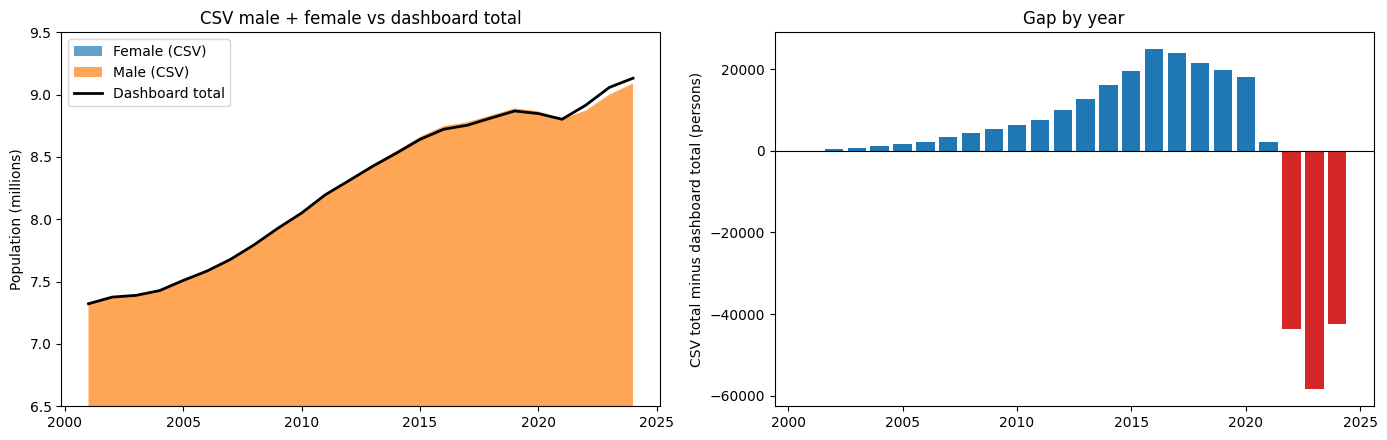

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.stackplot(by_sex.index, by_sex["female"] / 1e6, by_sex["male"] / 1e6, labels=["Female (CSV)", "Male (CSV)"], alpha=0.7)
ax1.plot(dashboard.index, dashboard / 1e6, color="black", lw=2, label="Dashboard total")
ax1.set_ylim(6.5, 9.5)
ax1.set_ylabel("Population (millions)")
ax1.set_title("CSV male + female vs dashboard total")
ax1.legend(loc="upper left")

ax2.bar(compare.index, compare["gap"], color=["tab:red" if g < 0 else "tab:blue" for g in compare["gap"]])
ax2.axhline(0, color="black", lw=0.8)
ax2.set_ylabel("CSV total minus dashboard total (persons)")
ax2.set_title("Gap by year")

plt.tight_layout()
plt.show()

## Does the gap exist inside the CSV?

Compares the sum of the age rows with the file's own `total` age row for each sex.

In [7]:
own_total = (
    london[
        (london["residence_type"] == "total")
        & london["sex"].isin(["male", "female"])
        & (london["age_group"] == "total")
    ]
    .groupby("sex")[YEAR_COLS]
    .sum()
    .T
)
own_total.index = own_total.index.astype(int)
internal = pd.DataFrame({"sum_of_ages": by_sex["csv_total"], "file_total_rows": own_total.sum(axis=1)})
internal["diff"] = internal["sum_of_ages"] - internal["file_total_rows"]
internal.round(0).loc[[2001, 2011, 2019, 2021, 2022, 2023, 2024]]

,sum_of_ages,file_total_rows,diff
2001,7322403,7322403,0
2011,8204376,8204376,0
2019,8888774,8888774,0
2021,8804761,8804761,0
2022,8871368,8871368,0
2023,8999705,8999705,0
2024,9089736,9089736,0


## Scaled series

Applies the CSV's female share to the dashboard total so that female + male equals the total in every year.

In [8]:
female_share = by_sex["female"] / by_sex["csv_total"]
scaled = pd.DataFrame({"total": dashboard})
scaled["female"] = (dashboard * female_share).round()
scaled["male"] = dashboard - scaled["female"]
scaled["female_share_pct"] = 100 * female_share

assert ((scaled["female"] + scaled["male"]) == scaled["total"]).all()
scaled.round(2).loc[[2001, 2011, 2019, 2021, 2022, 2023, 2024]]

,total,female,male,female_share_pct
2001,7322403.0,3725283.0,3597120.0,50.88
2011,8196696.0,4146530.0,4050166.0,50.59
2019,8868964.0,4555494.0,4313470.0,51.36
2021,8802611.0,4535014.0,4267597.0,51.52
2022,8915147.0,4600789.0,4314358.0,51.61
2023,9058151.0,4671105.0,4387046.0,51.57
2024,9132089.0,4702017.0,4430072.0,51.49


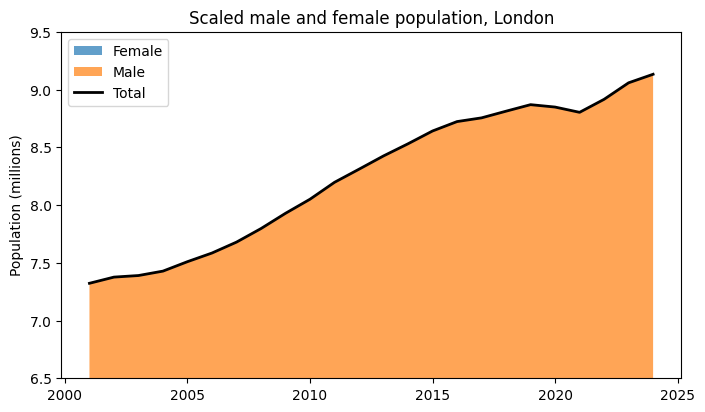

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.stackplot(scaled.index, scaled["female"] / 1e6, scaled["male"] / 1e6, labels=["Female", "Male"], alpha=0.7)
ax.plot(scaled.index, scaled["total"] / 1e6, color="black", lw=2, label="Total")
ax.set_ylim(6.5, 9.5)
ax.set_ylabel("Population (millions)")
ax.set_title("Scaled male and female population, London")
ax.legend(loc="upper left")
plt.show()

In [10]:
explorer = "/Users/user1/Downloads/20260902_explorer_tool"

## Explorer tool: historical population by sex

Reads the central-variant region population parquet files, partitioned by `year=`. Only years up to the latest estimate year are kept; later partitions are projections.

In [11]:
POPULATION_DIR = Path(explorer) / "output_pq/variant=central_ward/geography=region/component=population"
LATEST_YEAR = YEARS[-1]

parts = []
for year_dir in sorted(POPULATION_DIR.glob("year=*")):
    year = int(year_dir.name.split("=")[1])
    if year > LATEST_YEAR:
        continue
    df = pd.read_parquet(year_dir, columns=["age", "sex", "gss_code", "value"])
    parts.append(df[df["gss_code"] == LONDON_REGION].assign(year=year))

explorer_london = pd.concat(parts, ignore_index=True)
print(explorer_london["year"].min(), "to", explorer_london["year"].max(), explorer_london.shape)
explorer_london.head()

2011 to 2024 (2548, 5)


,age,sex,gss_code,value,year
0,0.0,female,E12000007,61316.0,2011
1,0.0,male,E12000007,64794.0,2011
2,1.0,female,E12000007,59238.0,2011
3,1.0,male,E12000007,62066.0,2011
4,2.0,female,E12000007,57261.0,2011


In [12]:
explorer_by_sex = explorer_london.pivot_table(index="year", columns="sex", values="value", aggfunc="sum")
explorer_by_sex["explorer_total"] = explorer_by_sex["female"] + explorer_by_sex["male"]

explorer_compare = pd.DataFrame(
    {
        "explorer_total": explorer_by_sex["explorer_total"],
        "dashboard_total": dashboard,
        "csv_total": by_sex["csv_total"],
    }
).dropna()
explorer_compare["gap_vs_dashboard"] = explorer_compare["explorer_total"] - explorer_compare["dashboard_total"]
explorer_compare["gap_vs_csv"] = explorer_compare["explorer_total"] - explorer_compare["csv_total"]
explorer_compare.round(0)

,explorer_total,dashboard_total,csv_total,gap_vs_dashboard,gap_vs_csv
2011,8196696.0,8196696.0,8204376,0.0,-7680.0
2012,8310139.0,8310139.0,8320154,0.0,-10015.0
2013,8425208.0,8425208.0,8437877,0.0,-12669.0
2014,8530308.0,8530308.0,8546348,0.0,-16040.0
2015,8641030.0,8641030.0,8660718,0.0,-19688.0
2016,8722485.0,8722485.0,8747385,0.0,-24900.0
2017,8754683.0,8754697.0,8778783,-14.0,-24100.0
2018,8812466.0,8812466.0,8834091,0.0,-21625.0
2019,8868964.0,8868964.0,8888774,0.0,-19810.0
2020,8848220.0,8848222.0,8866220,-2.0,-18000.0


In [14]:
explorer = "/Users/user1/Downloads/20260902_explorer_tool"

In [17]:
import os

base = "/Users/user1/Downloads/2024_based_population_projections"
print(os.listdir(base))

import pandas as pd

csv_path = "/Users/user1/Downloads/2024_based_population_projections/2024_ppt_10yr.csv"
df = pd.read_csv(csv_path)

print(df.head())

['2024_hht_15yr.csv', '2024_based_population_projections', '2024_ppt_10yr.csv', '2024_llt_5yr.csv']
    gss_code gss_name geography     measure population_projection_round  \
0  E92000001  England      ctry  population                  2024-based   
1  E92000001  England      ctry  population                  2024-based   
2  E92000001  England      ctry  population                  2024-based   
3  E92000001  England      ctry  population                  2024-based   
4  E92000001  England      ctry  population                  2024-based   

  population_projection_variant     sex     age_group          residence_type  \
0                      ppt_10yr  female   Age 0 to 14                   total   
1                      ppt_10yr  female   Age 0 to 14       private_household   
2                      ppt_10yr  female   Age 0 to 14  communal_establishment   
3                      ppt_10yr  female  Age 15 to 19                   total   
4                      ppt_10yr  female  Age

### ONS data

In [2]:
path = '/Users/user1/Downloads/myebtablesenglandwales20112025.xlsx'

import pandas as pd

df = pd.read_excel(path, sheet_name='MYEB2', header=1)
df.head()

,ladcode23,laname23,country,sex,age,population_2011,population_2012,population_2013,population_2014,population_2015,...,other_adjust_2016,other_adjust_2017,other_adjust_2018,other_adjust_2019,other_adjust_2020,other_adjust_2021,other_adjust_2022,other_adjust_2023,other_adjust_2024,other_adjust_2025
0,E06000001,Hartlepool,E,f,0,555,565,508,513,517,...,0,0,0,0,0,0,0,0,0,0
1,E06000001,Hartlepool,E,f,1,584,557,561,506,515,...,0,0,0,0,0,0,0,0,0,0
2,E06000001,Hartlepool,E,f,2,561,570,565,556,509,...,0,0,0,0,0,0,0,0,0,0
3,E06000001,Hartlepool,E,f,3,565,567,578,564,552,...,0,0,0,0,0,0,0,0,0,0
4,E06000001,Hartlepool,E,f,4,546,552,557,582,564,...,0,0,0,0,0,0,0,0,0,0


In [3]:
df
#filter for London codes
london_codes = {f'E090000{i:02d}' for i in range(1, 34)}
df = df[df['ladcode23'].isin(london_codes)].copy()

In [4]:
value_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
#exclude age
value_cols = [c for c in value_cols if c != "age"]

In [5]:
value_cols

['population_2011',
 'population_2012',
 'population_2013',
 'population_2014',
 'population_2015',
 'population_2016',
 'population_2017',
 'population_2018',
 'population_2019',
 'population_2020',
 'population_2021',
 'population_2022',
 'population_2023',
 'population_2024',
 'population_2025',
 'births_2012',
 'births_2013',
 'births_2014',
 'births_2015',
 'births_2016',
 'births_2017',
 'births_2018',
 'births_2019',
 'births_2020',
 'births_2021',
 'births_2022',
 'births_2023',
 'births_2024',
 'births_2025',
 'deaths_2012',
 'deaths_2013',
 'deaths_2014',
 'deaths_2015',
 'deaths_2016',
 'deaths_2017',
 'deaths_2018',
 'deaths_2019',
 'deaths_2020',
 'deaths_2021',
 'deaths_2022',
 'deaths_2023',
 'deaths_2024',
 'deaths_2025',
 'internal_in_2012',
 'internal_in_2013',
 'internal_in_2014',
 'internal_in_2015',
 'internal_in_2016',
 'internal_in_2017',
 'internal_in_2018',
 'internal_in_2019',
 'internal_in_2020',
 'internal_in_2021',
 'internal_in_2022',
 'internal_in_2023',


In [6]:
london_sex_age_totals_df = pd.DataFrame.groupby(df, ["sex", "age"], as_index=False)[value_cols].sum()


In [7]:
london_sex_age_totals_df

,sex,age,population_2011,population_2012,population_2013,population_2014,population_2015,population_2016,population_2017,population_2018,...,other_adjust_2016,other_adjust_2017,other_adjust_2018,other_adjust_2019,other_adjust_2020,other_adjust_2021,other_adjust_2022,other_adjust_2023,other_adjust_2024,other_adjust_2025
0,f,0,61387,64728,63233,61360,61719,62090,61038,58508,...,0,0,0,0,0,0,0,0,0,0
1,f,1,59413,60612,63425,61647,59507,59780,59837,58645,...,0,0,0,0,0,0,0,0,0,0
2,f,2,57725,58615,59562,61644,59738,57657,57415,57554,...,0,0,0,0,0,0,0,0,0,0
3,f,3,57204,57240,57967,58429,60017,58063,55846,55471,...,0,0,0,0,0,0,0,0,0,0
4,f,4,54548,56875,56805,57252,57476,58558,56231,54129,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177,m,86,6539,6740,6872,7044,7237,7636,7465,7934,...,0,0,0,0,0,0,0,0,0,0
178,m,87,5782,5769,5901,6108,6145,6340,6699,6468,...,0,0,0,0,0,0,0,0,0,0
179,m,88,4858,5045,5008,5163,5274,5393,5535,5752,...,0,0,0,0,0,0,0,0,0,0
180,m,89,4164,4159,4283,4273,4317,4479,4573,4716,...,0,0,0,0,0,0,0,0,0,0


In [8]:
#save london_sex_age_totals_df to a CSV file
london_sex_age_totals_df.to_csv("/Users/user1/Downloads/london_sex_age_totals.csv", index=False)

In [9]:
# Total population by sex over time (all ages)
import plotly.express as px

year_cols = [c for c in df.columns if c.startswith("population_")]
sex_totals = df[df["sex"].isin(["f", "m"])].groupby("sex")[year_cols].sum().T
sex_totals.index = sex_totals.index.str.replace("population_", "").astype(int)
sex_totals = sex_totals.rename(columns={"f": "Female", "m": "Male"}).reset_index().rename(columns={"index": "year"})
#add a line for total
sex_totals["Total"] = sex_totals["Female"] + sex_totals["Male"]

fig = px.line(
    sex_totals,
    x="year",
    y=["Female", "Male", "Total"],
    title="London population by sex",
    labels={"variable": "Sex", "value": "Population", "year": "Year"},
    hover_data={"year": True},
)
fig.update_traces(mode="lines+markers", hovertemplate="Year: %{x}<br>Sex: %{fullData.name}<br>Population: %{y:,}<extra></extra>")
fig.show()


In [10]:
london_sex_age_totals_df.columns.tolist()

['sex',
 'age',
 'population_2011',
 'population_2012',
 'population_2013',
 'population_2014',
 'population_2015',
 'population_2016',
 'population_2017',
 'population_2018',
 'population_2019',
 'population_2020',
 'population_2021',
 'population_2022',
 'population_2023',
 'population_2024',
 'population_2025',
 'births_2012',
 'births_2013',
 'births_2014',
 'births_2015',
 'births_2016',
 'births_2017',
 'births_2018',
 'births_2019',
 'births_2020',
 'births_2021',
 'births_2022',
 'births_2023',
 'births_2024',
 'births_2025',
 'deaths_2012',
 'deaths_2013',
 'deaths_2014',
 'deaths_2015',
 'deaths_2016',
 'deaths_2017',
 'deaths_2018',
 'deaths_2019',
 'deaths_2020',
 'deaths_2021',
 'deaths_2022',
 'deaths_2023',
 'deaths_2024',
 'deaths_2025',
 'internal_in_2012',
 'internal_in_2013',
 'internal_in_2014',
 'internal_in_2015',
 'internal_in_2016',
 'internal_in_2017',
 'internal_in_2018',
 'internal_in_2019',
 'internal_in_2020',
 'internal_in_2021',
 'internal_in_2022',
 'int

In [11]:
london_sex_age_totals_df['births_2019'].sum()
london_sex_age_totals_df['deaths_2020'].sum()

np.int64(59192)

In [12]:
path = "/Users/user1/Downloads/london_sex_age_totals.csv"
london_sex_age_totals_df = pd.read_csv(path)

In [13]:
london_sex_age_totals_df
#select population 2025
population_2025 =london_sex_age_totals_df[['sex', 'age', 'population_2025']]

In [ ]:
population_2025

,sex,age,population_2025
0,f,0,50897
1,f,1,50712
2,f,2,49489
3,f,3,51252
4,f,4,48121
...,...,...,...
177,m,86,8565
178,m,87,7754
179,m,88,6603
180,m,89,5559


In [15]:
population_2025_bin = population_2025.copy()
#5 year age groups
population_2025_bin['age_group'] = (population_2025_bin['age'] // 5) * 5

In [16]:
#sum
population_2025_bin_sum = population_2025_bin.groupby('age_group').sum()

In [17]:
population_2025_bin_sum
#remove sex and age columns
population_2025_bin_sum = population_2025_bin_sum.drop(columns=['sex', 'age'])

In [18]:
population_2025_bin_sum

,population_2025
age_group,
0,513549
5,500540
10,510129
15,512961
20,645733
25,888221
30,812771
35,733920
40,672903


<Axes: xlabel='age_group'>

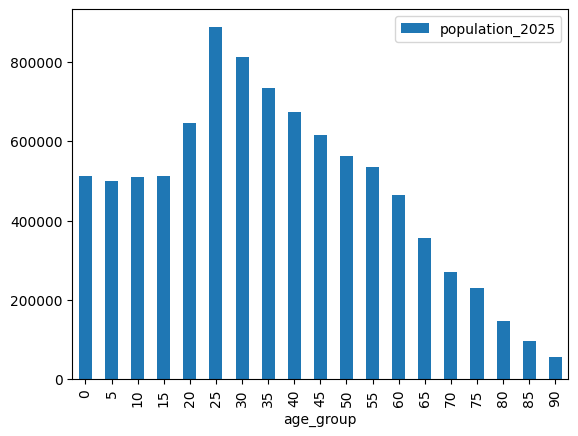

In [19]:
#population_2025_bin_sum bar 
population_2025_bin_sum.plot(kind='bar')    

<Axes: xlabel='age_group'>

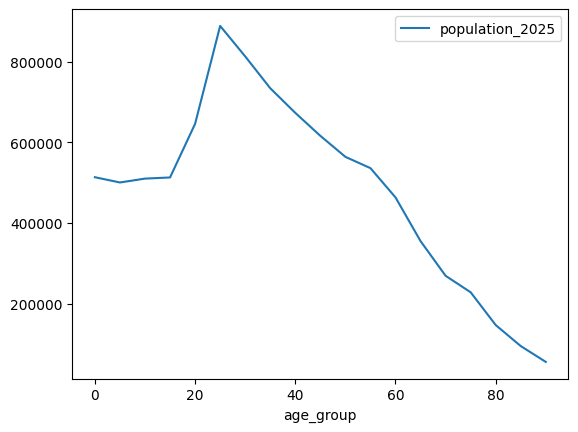

In [20]:
#make a line chart from population_2025
population_2025_bin_sum.plot(kind='line')

In [36]:
population_total = population_2025.copy()
#combine male and female populations
population_total["population_2025"] = population_total.groupby("age")["population_2025"].transform("sum")
population_total = population_total.drop_duplicates(subset="age")

In [ ]:
    population_total

,sex,age,population_2025
0,f,0,104288
1,f,1,103759
2,f,2,101893
3,f,3,105481
4,f,4,98128
...,...,...,...
86,f,86,21354
87,f,87,19468
88,f,88,16784
89,f,89,14483


In [38]:
#line graph
import plotly.express as px
fig = px.line(
        population_total,
        x="age",
        y="population_2025",
        markers=True,
        title="London population by 5-year age groups, 2025",
        
    )
fig.show()

In [21]:
fig = px.line(
    population_2025_bin_sum.reset_index(),
    x="age_group",
    y="population_2025",
    markers=True,
    title="London population by age group, 2025",
    labels={"age_group": "Age group", "population_2025": "Population"},
)
fig.show()

### --------------------------------------------------------- Json Data

In [24]:
import json
import pandas as pd
import plotly.express as px
from pathlib import Path

repo_root = Path("/Users/user1/Documents/Londons-Population-Site")
data_path = repo_root / "src/lib/data/londonAgeStructure.json"

with data_path.open() as f:
    london_age_structure = json.load(f)

df = pd.DataFrame(london_age_structure)
df = df[df["b"] == "2025"].copy()
df["age"] = df["xd"].astype(int)
df["population"] = df["y"]

fig = px.line(
    df,
    x="age",
    y="population",
    markers=True,
    title="London population by single year of age, 2025",
    labels={"age": "Age", "population": "Population"},
)

fig.show()

In [25]:
import json
import pandas as pd
import plotly.express as px
from pathlib import Path

repo_root = Path("/Users/user1/Documents/Londons-Population-Site")
data_path = repo_root / "src/lib/data/londonAgeStructure.json"

with data_path.open() as f:
    london_age_structure = json.load(f)

df = pd.DataFrame(london_age_structure)
df = df[df["b"] == "2025"].copy()
df["age"] = df["xd"].astype(int)
df["population"] = df["y"]

# Create 5-year age bins
def age_bin(age):
    lower = (age // 5) * 5
    upper = lower + 4
    return f"{lower}-{upper}"

df["age_bin"] = df["age"].map(age_bin)

df_5yr = (
    df.groupby("age_bin", as_index=False)["population"]
      .sum()
      .sort_values("age_bin")
)

fig = px.bar(
    df_5yr,
    x="age_bin",
    y="population",
    title="London population by 5-year age bins, 2025",
    labels={"age_bin": "Age group", "population": "Population"},
    color_discrete_sequence=["#2E86DE"]
)

fig.show()